> **Historical result:** This notebook was run before the Phase 3 accounting correction. Its saved outputs and the cost conventions described below are retained for comparison and are stale. See `09_phase3_evaluation.ipynb` for corrected results; re-executing these cells will use the updated backtester and may not match the descriptions below.


# Phase 3: Transaction-cost sensitivity

Compare the monthly momentum strategy under 0, 5, 10, 25, and 50 basis points (bps). One basis point is 0.01%; the rate is the cost **per unit of the turnover reported by the current function**, not necessarily a per-side brokerage rate. Results use saved prices and do not download data or overwrite project data.

**Interpretation:** The current function calculates turnover as half the sum of absolute changes in stock weights. Starting from cash therefore records 50% turnover for the initial purchase. It compounds daily returns at equal target weights but calculates subsequent turnover using drifted weights, so the return and turnover models are inconsistent. The results below illustrate this implementation; they should not yet be treated as a realistic estimate of actual trading costs. Current constituents also introduce survivorship bias, and the experiment is in-sample.

In [ ]:
from pathlib import Path
import sys
from functools import partial
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / "src").is_dir():
    root = root.parent
if not (root / "src" / "backtest.py").is_file():
    raise FileNotFoundError("Open this notebook from the project root or notebooks folder.")
sys.path.insert(0, str(root))
from src.backtest import run_factor_backtest, momentum_score

prices = pd.read_csv(root / "data" / "prices.csv", index_col=0, parse_dates=True).sort_index()
print(f"Saved prices: {prices.index.min().date()} to {prices.index.max().date()}, {len(prices.columns)} stocks")

Saved prices: 2018-01-02 to 2024-12-31, 30 stocks


In [2]:
cost_assumptions = [0, 5, 10, 25, 50]  # bps per unit of reported turnover
results = {}
for bps in cost_assumptions:
    returns, holdings, turnover = run_factor_backtest(
        prices, score_function=partial(momentum_score, lookback=252),
        top_n=5, strategy_name=f"Momentum ({bps} bps)",
        transaction_cost_bps=bps,
    )
    results[bps] = {"returns": returns, "holdings": holdings, "turnover": turnover}

assert all(results[b]["returns"].index.equals(results[0]["returns"].index) for b in cost_assumptions)
assert all(results[b]["holdings"].equals(results[0]["holdings"]) for b in cost_assumptions)
assert all((results[b]["returns"] <= results[0]["returns"] + 1e-12).all() for b in cost_assumptions)
print(f"Holding periods: {len(results[0]['returns'])}")
print(f"Initial recorded turnover: {results[0]['turnover']['turnover'].iloc[0]:.1%}")

Holding periods: 71
Initial recorded turnover: 50.0%


## Compare outcomes

CAGR uses the number of monthly return observations; maximum drawdown includes the initial $1 investment. Annualized volatility and Sharpe use monthly returns, with a zero risk-free rate. Total cost fractions are summed for context and are not compounded dollar costs.

In [3]:
rows = []
for bps, result in results.items():
    r = result["returns"]
    t = result["turnover"]
    wealth = (1 + r).cumprod()
    peak = wealth.cummax().clip(lower=1)
    volatility = r.std() * (12 ** 0.5)
    rows.append({
        "Cost (bps)": bps,
        "Ending wealth ($1 start)": wealth.iloc[-1],
        "CAGR": wealth.iloc[-1] ** (12 / len(r)) - 1,
        "Annual volatility": volatility,
        "Sharpe (zero risk-free)": r.mean() * 12 / volatility,
        "Max drawdown": (wealth / peak - 1).min(),
        "Average monthly turnover": t["turnover"].mean(),
        "Sum of cost fractions": t["transaction_cost"].sum(),
    })
comparison = pd.DataFrame(rows).set_index("Cost (bps)")
comparison.round(4)

,Ending wealth ($1 start),CAGR,Annual volatility,Sharpe (zero risk-free),Max drawdown,Average monthly turnover,Sum of cost fractions
Cost (bps),,,,,,,
0,3.3582,0.2272,0.1984,1.1360,-0.1775,0.2373,0.0000
5,3.3300,0.2255,0.1984,1.1289,-0.1781,0.2373,0.0084
10,3.3020,0.2237,0.1983,1.1219,-0.1786,0.2373,0.0168
25,3.2196,0.2185,0.1982,1.1006,-0.1803,0.2373,0.0421
50,3.0866,0.2098,0.1979,1.0652,-0.1830,0.2373,0.0842


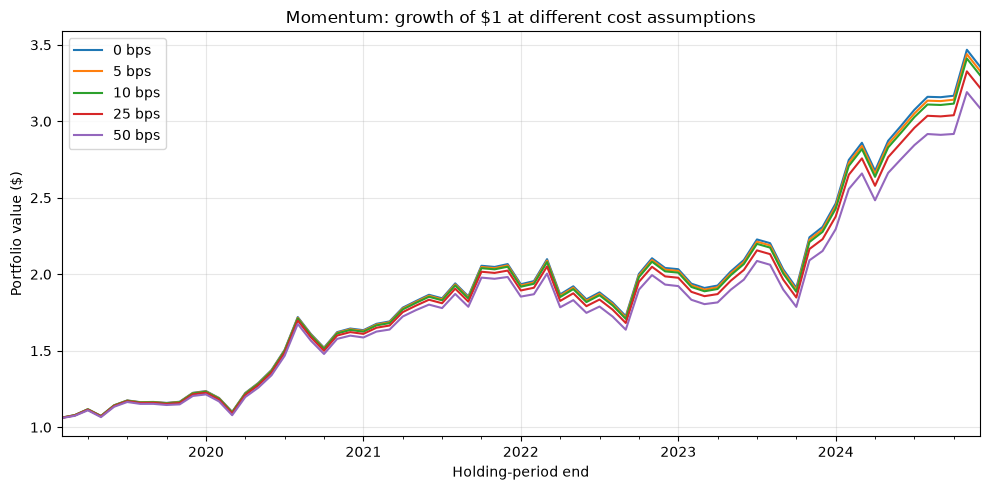

In [4]:
wealth = pd.DataFrame({f"{bps} bps": (1 + result["returns"]).cumprod() for bps, result in results.items()})
ax = wealth.plot(figsize=(10, 5), title="Momentum: growth of $1 at different cost assumptions")
ax.set_ylabel("Portfolio value ($)")
ax.set_xlabel("Holding-period end")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Inspect turnover

The 10 bps case shows the recorded turnover, gross return, cost fraction, and net return for each rebalance. Turnover and holdings are the same across cost assumptions because costs do not affect the selection process.

In [5]:
results[10]["turnover"].head(10).round(4)

/var/folders/nk/2g8vnzd97ml2xdlpypkk250r0000gn/T/ipykernel_28494/725416047.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  results[10]["turnover"].head(10).round(4)


,formation_date,holding_until,turnover,transaction_cost,gross_return,net_return
0,2019-01-31,2019-02-28,0.5000,0.0005,0.0624,0.0619
1,2019-02-28,2019-03-31,0.4031,0.0004,0.0159,0.0155
2,2019-03-31,2019-04-30,0.4094,0.0004,0.0357,0.0353
3,2019-04-30,2019-05-31,0.2184,0.0002,-0.0391,-0.0393
4,2019-05-31,2019-06-30,0.2021,0.0002,0.0647,0.0644
5,2019-06-30,2019-07-31,0.0043,0.0000,0.0275,0.0275
6,2019-07-31,2019-08-31,0.2116,0.0002,-0.0096,-0.0098
7,2019-08-31,2019-09-30,0.2000,0.0002,0.0012,0.0010
8,2019-09-30,2019-10-31,0.2073,0.0002,-0.0054,-0.0056
9,2019-10-31,2019-11-30,0.6000,0.0006,0.0066,0.0060
